# 02. Preprocessing

**Proyek akhir Jaringan Saraf Tiruan: MLP dengan backpropagation**

Notebook ini mengubah temuan EDA menjadi pipeline preprocessing yang menghasilkan input siap pakai untuk MLP. Semua parameter (median, kategori, batas capping, scaler) dipelajari **hanya dari train**, lalu diterapkan tanpa perubahan ke validation dan test.

Cakupan: handling missing value, encoding, normalisasi, penanganan outlier, feature selection, dan keputusan balancing. Belum ada training MLP di notebook ini.

## 1. Setup

Konfigurasi berasal dari `configs/feature_contract.json` (daftar fitur) dan `configs/preprocessing.json` (resep). Array hasil preprocessing disimpan di `data/processed/`, pipeline yang sudah di-fit di `models/preprocessing/`, dan keduanya tidak masuk Git.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Image

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()), None)
if REPO is None:
    raise RuntimeError("Jalankan dari root proyek atau folder notebooks.")
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
from ev_battery.paths import prepare_workspace

ROOT = prepare_workspace(REPO)
from ev_battery.preprocessing import run_preprocessing, load_prepared_split, TARGET, FORBIDDEN

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.precision", 6)
result = run_preprocessing(ROOT)
train = result["splits"]["train"]
variants = result["variants"]


def show(name):
    display(Image(filename=str(result["output"] / name), width=1100))


print("Semua fit hanya pada train. Validation dan test hanya di-transform.")
display(result["summary"])

Semua fit hanya pada train. Validation dan test hanya di-transform.


,recipe,split,rows,batteries,raw_features,input_neurons,numeric_missing_after,finite,dtype
0,baseline_standard,train,34929,1820,21,67,0,True,float32
1,baseline_standard,validation,7499,390,21,67,0,True,float32
2,baseline_standard,test,7572,390,21,67,0,True,float32
3,baseline_minmax,train,34929,1820,21,67,0,True,float32
4,baseline_minmax,validation,7499,390,21,67,0,True,float32
5,baseline_minmax,test,7572,390,21,67,0,True,float32
6,log_sensor_caps,train,34929,1820,21,67,0,True,float32
7,log_sensor_caps,validation,7499,390,21,67,0,True,float32
8,log_sensor_caps,test,7572,390,21,67,0,True,float32
9,compact_log_sensor_caps,train,34929,1820,19,63,0,True,float32


## 2. Empat resep preprocessing

| Resep | Isi | Tujuan |
|---|---|---|
| `baseline_standard` | 21 fitur, imputasi median plus indikator missing, one-hot, standardisasi | Acuan paling sederhana |
| `baseline_minmax` | Sama, tetapi fitur numerik di-scale ke [0, 1] dengan min dan max train | Normalisasi seperti `minmax_scale` di modul |
| `log_sensor_caps` | Standardisasi, ditambah log transform pada 5 fitur berekor panjang dan capping 3 sensor | Menguji penanganan outlier |
| `compact_log_sensor_caps` | Seperti `log_sensor_caps`, tanpa 2 fitur yang redundan | Menguji feature selection |

Keempat resep ditetapkan sebelum training dan dibandingkan pada validation di notebook 03.

In [2]:
specs = []
for name, spec in result["settings"]["recipes"].items():
    prep = variants[name]["preprocessor"]
    specs.append(
        {
            "recipe": name,
            "raw_features": len(prep.required_columns),
            "input_neurons": prep.n_features_out_,
            "scaler": prep.scaler,
            "dropped": ", ".join(spec["drop_features"]) or "Tidak ada",
            "log": ", ".join(spec["log_features"]) or "Tidak ada",
            "caps": ", ".join(spec["clip_features"]) or "Tidak ada",
        }
    )
display(pd.DataFrame(specs))

,recipe,raw_features,input_neurons,scaler,dropped,log,caps
0,baseline_standard,21,67,standard,Tidak ada,Tidak ada,Tidak ada
1,baseline_minmax,21,67,minmax,Tidak ada,Tidak ada,Tidak ada
2,log_sensor_caps,21,67,standard,Tidak ada,"cycle_count, total_energy_throughput_kwh, avg_daily_distance_km, altitude_m, serv...","avg_charging_power_kw, avg_ambient_temp_c, peak_temp_during_fast_charge_c"
3,compact_log_sensor_caps,19,63,standard,"total_energy_throughput_kwh, peak_temp_during_fast_charge_c","cycle_count, avg_daily_distance_km, altitude_m, service_count","avg_charging_power_kw, avg_ambient_temp_c"


## 3. Pencegahan leakage

Kolom yang dilarang (`capacity_fade_pct`, target alternatif, ID, tanggal mentah, dan proxy sensor) tidak boleh masuk pipeline. Pipeline juga menolak input yang kolomnya kurang atau berlebih, sehingga target tidak bisa terselip tanpa sengaja.

In [3]:
base = variants["baseline_standard"]["preprocessor"]
for name, entry in variants.items():
    assert set(entry["preprocessor"].required_columns).isdisjoint(FORBIDDEN)
    assert entry["preprocessor"].fit_rows_ == 34929
print("PASS: ketiga resep tidak memuat ID, target, tanggal, atau proxy yang dilarang.")
display(pd.DataFrame({"input_column": base.required_columns}))

PASS: ketiga resep tidak memuat ID, target, tanggal, atau proxy yang dilarang.


,input_column
0,pack_capacity_kwh
1,battery_age_days
2,cycle_count
3,avg_daily_distance_km
4,avg_charging_power_kw
5,fast_charge_ratio
6,avg_depth_of_discharge_pct
7,avg_state_of_charge_pct
8,charge_cycles_per_month
9,total_energy_throughput_kwh


## 4. Data cleaning tanpa menghapus baris

Nilai yang melanggar definisi diubah menjadi missing, misalnya rasio di luar 0 sampai 1, persentase di luar 0 sampai 100, atau `recall_flag` selain 0/1. Nilai ekstrem yang masih valid tetap dipertahankan, dan tidak ada baris yang dihapus.

In [4]:
display(
    pd.DataFrame(
        {name: entry["preprocessor"].invalid_counts_train_ for name, entry in variants.items()}
    ).fillna("tidak dipakai")
)
assert all(sum(entry["preprocessor"].invalid_counts_train_.values()) == 0 for entry in variants.values())
print("Pada CSV train saat ini tidak ditemukan nilai yang melanggar aturan cleaning tersebut.")

,baseline_standard,baseline_minmax,log_sensor_caps,compact_log_sensor_caps
pack_capacity_kwh,0,0,0,0.0
battery_age_days,0,0,0,0.0
cycle_count,0,0,0,0.0
avg_daily_distance_km,0,0,0,0.0
avg_charging_power_kw,0,0,0,0.0
fast_charge_ratio,0,0,0,0.0
avg_depth_of_discharge_pct,0,0,0,0.0
avg_state_of_charge_pct,0,0,0,0.0
charge_cycles_per_month,0,0,0,0.0
total_energy_throughput_kwh,0,0,0,tidak dipakai


Pada CSV train saat ini tidak ditemukan nilai yang melanggar aturan cleaning tersebut.


## 5. Handling missing value

- **Numerik:** diisi median train, ditambah kolom indikator `missing__<fitur>` bernilai 1 jika aslinya kosong.
- **Kategori:** kategori eksplisit `__MISSING__`, bukan diisi modus.
- **Biner (`recall_flag`):** diisi modus train, ditambah indikator missing.

Indikator dibuat untuk semua fitur, termasuk yang lengkap di train, agar missing value baru saat inferensi tetap tertangani.

In [5]:
params = pd.read_csv(result["output"] / "baseline_standard_numeric_parameters.csv")
display(params[["feature", "median_train_original"]])
for c in base.numeric_features:
    assert np.isclose(base.medians_[c], train[c].median())
assert base.binary_modes_["recall_flag"] == train.recall_flag.mode().iloc[0]
print("PASS: median dan modus sesuai train saja.")
probe = train.loc[:, base.required_columns].iloc[[0]].copy()
probe["cycle_count"] = np.nan
probe_X = base.transform(probe)
flag = list(base.get_feature_names_out()).index("missing__cycle_count")
assert probe_X[0, flag] == 1
assert np.isfinite(probe_X).all()
print("Probe missing value baru berhasil. Ini contoh uji, bukan perubahan dataset.")

,feature,median_train_original
0,pack_capacity_kwh,72.500
1,battery_age_days,418.000
2,cycle_count,372.000
3,avg_daily_distance_km,39.300
4,avg_charging_power_kw,28.600
5,fast_charge_ratio,0.272
6,avg_depth_of_discharge_pct,65.000
7,avg_state_of_charge_pct,67.900
8,charge_cycles_per_month,19.000
9,total_energy_throughput_kwh,24155.300


PASS: median dan modus sesuai train saja.
Probe missing value baru berhasil. Ini contoh uji, bukan perubahan dataset.


## 6. Encoding kategori

One-hot encoding membuat satu kolom per kategori tanpa urutan buatan (misalnya LFP tidak dianggap lebih kecil dari NMC). Kategori yang belum pernah terlihat saat training menjadi blok bernilai nol semua, sehingga jumlah kolom input tetap sama. Ini berbeda dengan missing value yang punya kolom one-hot sendiri.

In [6]:
display(pd.read_csv(result["output"] / "baseline_standard_categories.csv"))
probe = train.loc[:, base.required_columns].iloc[[0, 0]].copy().reset_index(drop=True)
probe.loc[0, "chemistry"] = "NEW_CHEMISTRY_FOR_TEST"
probe.loc[1, "chemistry"] = None
state_before = joblib.hash(base)
X_probe = base.transform(probe)
chem_idx = [i for i, n in enumerate(base.get_feature_names_out()) if n.startswith("cat__chemistry_")]
assert X_probe[0, chem_idx].sum() == 0
assert X_probe[1, chem_idx].sum() == 1
assert joblib.hash(base) == state_before
print("PASS: unknown dan missing berbeda, lebar tetap, parameter tidak berubah.")
display(pd.Series(base.diagnostic(probe)["unknown_categories"], name="unknown_probe").to_frame())

,feature,category,block_index
0,chemistry,LFP,0
1,chemistry,LMO,1
2,chemistry,NCA,2
3,chemistry,NMC,3
4,chemistry,__MISSING__,4
5,manufacturer,Amperion,0
6,manufacturer,CellTech,1
7,manufacturer,GigaWatt Labs,2
8,manufacturer,IonFlux,3
9,manufacturer,NexCell,4


PASS: unknown dan missing berbeda, lebar tetap, parameter tidak berubah.


,unknown_probe
chemistry,1
manufacturer,0
vehicle_model,0
climate_zone,0
bms_firmware_version,0


## 7. Penanganan outlier

Resep alternatif menerapkan dua langkah yang terarah:

- **Signed log1p** pada siklus, energi, jarak harian, altitude, dan jumlah servis untuk merapatkan ekor panjang.
- **Capping** pada daya pengisian, suhu lingkungan, dan suhu puncak di kuantil 0,5% dan 99,5% train.

Outlier tidak dihapus karena nilai ekstrem bisa jadi baterai yang memang terdegradasi. Resep baseline tanpa capping tetap disediakan sebagai pembanding.

,feature,median_train_original,cap_lower_train,cap_upper_train,signed_log1p,scaler,scaler_center_train,scaler_spread_train
0,pack_capacity_kwh,72.500,NaN,NaN,False,standard,72.625386,14.069199
1,battery_age_days,418.000,NaN,NaN,False,standard,547.234819,463.060142
2,cycle_count,372.000,NaN,NaN,True,standard,5.712526,1.308864
3,avg_daily_distance_km,39.300,NaN,NaN,True,standard,3.667027,0.751704
4,avg_charging_power_kw,28.600,3.000,92.3,False,standard,31.789018,17.165768
5,fast_charge_ratio,0.272,NaN,NaN,False,standard,0.291768,0.165757
6,avg_depth_of_discharge_pct,65.000,NaN,NaN,False,standard,64.768158,15.361672
7,avg_state_of_charge_pct,67.900,NaN,NaN,False,standard,67.641189,9.809927
8,charge_cycles_per_month,19.000,NaN,NaN,False,standard,20.253194,10.079811
9,total_energy_throughput_kwh,24155.300,NaN,NaN,True,standard,9.890457,1.339541


,baris_train_di_cap_per_fitur
avg_charging_power_kw,175
avg_ambient_temp_c,214
peak_temp_during_fast_charge_c,331


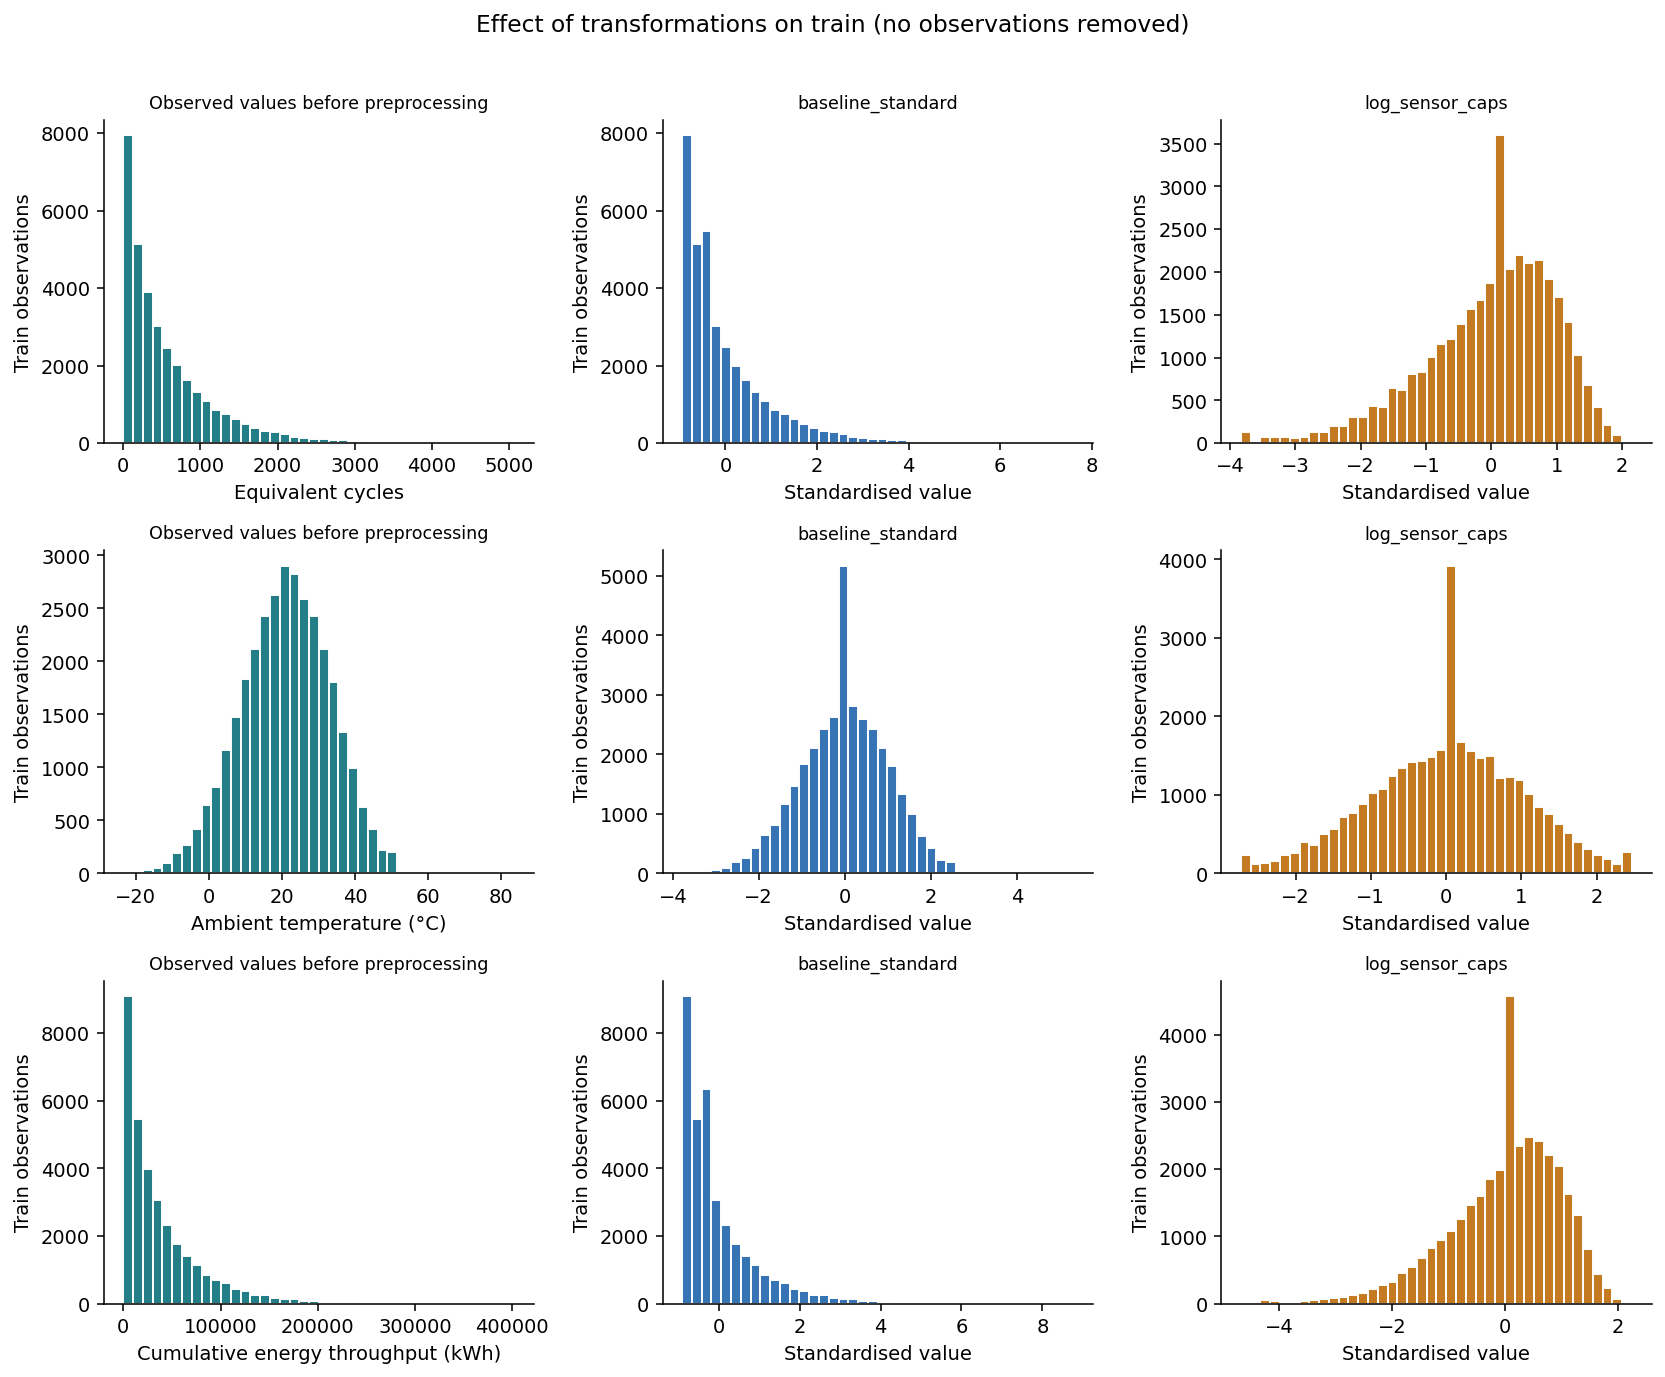

In [7]:
robust = variants["log_sensor_caps"]["preprocessor"]
display(pd.read_csv(result["output"] / "log_sensor_caps_numeric_parameters.csv"))
for c, (low, high) in robust.clip_bounds_.items():
    expected = train[c].quantile([0.005, 0.995]).to_numpy()
    np.testing.assert_allclose([low, high], expected)
display(
    pd.Series(
        robust.diagnostic(variants["log_sensor_caps"]["train_raw"])["clipped_rows_by_feature"],
        name="baris_train_di_cap_per_fitur",
    ).to_frame()
)
show("01_before_after_train.png")

**Interpretasi:** log transform merapatkan ekor panjang tanpa mengubah urutan nilai, sedangkan capping membatasi pengaruh nilai sensor ekstrem. Lonjakan di sekitar median berasal dari imputasi dan ditandai oleh indikator missing.

## 8. Normalisasi

Dua metode normalisasi dibandingkan:

```text
standardisasi: x_scaled = (x - mean_train) / std_train
min-max:       x_scaled = (x - min_train) / (max_train - min_train)
```

Min-max adalah metode yang dipakai di modul (`minmax_scale`), sedangkan standardisasi dipakai di LC 5. Keduanya di-fit hanya pada train, setelah imputasi, log, dan capping. Kolom one-hot, biner, dan indikator tetap bernilai 0/1. Tujuannya agar semua fitur numerik berada pada skala yang sama sehingga gradient descent lebih stabil.

,recipe,scaler,max_abs_mean,max_abs_std_minus_one,min_train,max_train
0,baseline_standard,standard,1.096395e-08,7.829885e-09,NaN,NaN
1,baseline_minmax,minmax,NaN,NaN,0.0,1.0
2,log_sensor_caps,standard,2.426617e-08,8.476567e-09,NaN,NaN
3,compact_log_sensor_caps,standard,2.426617e-08,8.476567e-09,NaN,NaN


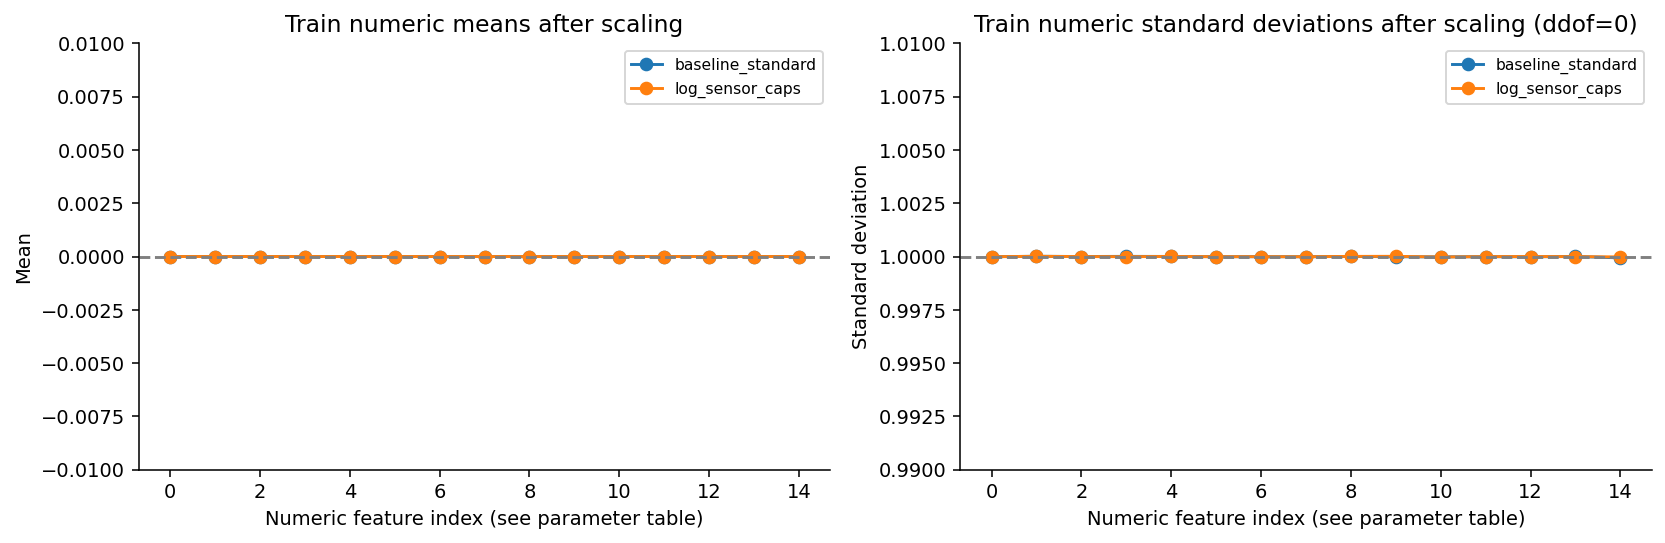

In [8]:
scale_rows = []
for name, entry in variants.items():
    prep = entry["preprocessor"]
    numeric = entry["train_X"][:, : len(prep.numeric_features)].astype(np.float64)
    row = {"recipe": name, "scaler": prep.scaler}
    if prep.scaler == "standard":
        row["max_abs_mean"] = np.abs(numeric.mean(axis=0)).max()
        row["max_abs_std_minus_one"] = np.abs(numeric.std(axis=0, ddof=0) - 1).max()
        assert row["max_abs_mean"] < 1e-6 and row["max_abs_std_minus_one"] < 1e-6
    else:
        row["min_train"] = numeric.min()
        row["max_train"] = numeric.max()
        assert np.isclose(numeric.min(axis=0), 0).all() and np.isclose(numeric.max(axis=0), 1).all()
    scale_rows.append(row)
display(pd.DataFrame(scale_rows))
show("02_scaler_train_checks.png")

## 9. Feature selection

Feature selection dilakukan dalam dua lapis:

1. **Berbasis leakage:** kolom yang membocorkan target dan proxy sensor dikeluarkan (notebook 00).
2. **Berbasis redundansi:** resep `compact` membuang `total_energy_throughput_kwh` (korelasi 0,984 dengan siklus) dan `peak_temp_during_fast_charge_c` (0,920 dengan suhu lingkungan).

Fitur tidak dibuang hanya karena korelasinya dengan target rendah, karena MLP dapat memanfaatkan hubungan nonlinear. Apakah resep `compact` lebih baik ditentukan dari hasil validation.

,recipe,raw_features,input_neurons,illustrative_parameters_hidden_64_32
0,baseline_standard,21,67,6465
1,baseline_minmax,21,67,6465
2,log_sensor_caps,21,67,6465
3,compact_log_sensor_caps,19,63,6209


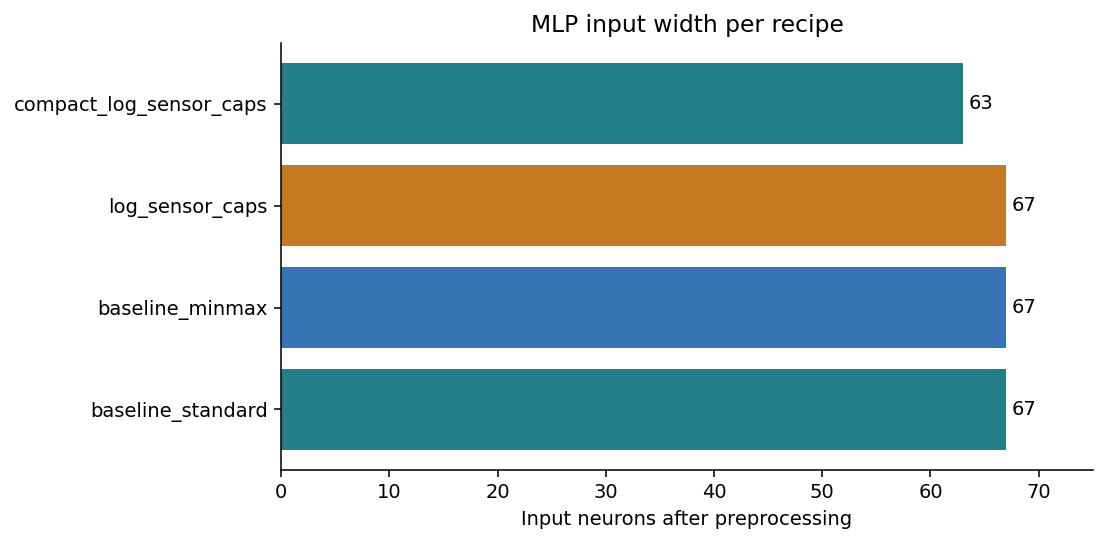

In [9]:
dimensions = []
for name, entry in variants.items():
    prep = entry["preprocessor"]
    p = prep.n_features_out_
    dimensions.append(
        {
            "recipe": name,
            "raw_features": len(prep.required_columns),
            "input_neurons": p,
            "illustrative_parameters_hidden_64_32": (p * 64 + 64) + (64 * 32 + 32) + (32 + 1),
        }
    )
display(pd.DataFrame(dimensions))
show("03_input_dimensions.png")

**Jumlah input neuron:** resep lengkap menghasilkan 67 input, yaitu 15 numerik, 15 indikator numerik, 1 biner, 1 indikator biner, dan 35 kolom one-hot. Resep `compact` menghasilkan 63 input karena dua fitur numerik beserta indikatornya dibuang.

## 10. Target dan balancing

Target SOH juga distandardisasi (fit pada train) agar output neuron linear mulai belajar di sekitar nol. Model dilatih dengan `y_scaled`, lalu prediksi dikembalikan ke satuan SOH asli sebelum menghitung MAE dan RMSE.

**Balancing tidak diterapkan.** Target bersifat kontinu, jadi tidak ada kelas yang perlu diseimbangkan, dan SMOTE atau oversampling tidak berlaku. Ketimpangan distribusi SOH ditangani dengan melaporkan error per rentang SOH saat evaluasi.

In [10]:
target_scaler = result["target_scaler"]
assert np.isclose(target_scaler.mean_[0], train[TARGET].mean())
assert np.isclose(target_scaler.scale_[0], train[TARGET].std(ddof=0))
scaled = target_scaler.transform(train[[TARGET]]).ravel().astype(np.float32)
restored = target_scaler.inverse_transform(scaled.astype(float).reshape(-1, 1)).ravel()
max_error = np.max(np.abs(restored - train[TARGET].to_numpy()))
assert max_error < 1e-5
display(
    pd.Series(
        {
            "mean_target_train": target_scaler.mean_[0],
            "scale_target_train": target_scaler.scale_[0],
            "roundtrip_max_error_pp": max_error,
        }
    ).to_frame("nilai")
)
print("Tidak ada SMOTE, sampling ulang, clipping y, atau penghapusan SOH rendah.")

,nilai
mean_target_train,92.918747
scale_target_train,7.192673
roundtrip_max_error_pp,0.000002


Tidak ada SMOTE, sampling ulang, clipping y, atau penghapusan SOH rendah.


## 11. Verifikasi array

Setiap split dan resep diperiksa: dtype float32, ukuran sesuai, tidak ada NaN, urutan fitur konsisten, dan ID tidak tercampur antarsplit. Validation dan test hanya diperiksa kesiapannya, tanpa menghitung distribusi target atau skor.

In [11]:
for recipe in variants:
    for split, raw in result["splits"].items():
        data, bundle = load_prepared_split(recipe, split, ROOT)
        assert data["X"].dtype == np.float32
        assert data["X"].shape == (len(raw), len(bundle["feature_names"]))
        assert np.isfinite(data["X"]).all() and np.isfinite(data["y_scaled"]).all()
        np.testing.assert_array_equal(data["observation_id"], raw.observation_id.to_numpy(dtype=str))
        np.testing.assert_array_equal(data["battery_id"], raw.battery_id.to_numpy(dtype=str))
        np.testing.assert_array_equal(data["y_original"], raw[TARGET].to_numpy())
        assert not set(bundle["required_columns"]).intersection(FORBIDDEN)
print("PASS: sembilan array split/resep valid, ID dan target selaras, tidak ada kebocoran kolom.")
display(result["checks"])

PASS: sembilan array split/resep valid, ID dan target selaras, tidak ada kebocoran kolom.


,recipe,check,result
0,baseline_standard,transform_state_unchanged,PASS
1,baseline_standard,all_split_float32_finite_and_same_width,PASS
2,baseline_standard,target_inverse_max_error_pp,0.000001712
3,baseline_standard,serialization_exact_first_16_rows,PASS
4,baseline_minmax,transform_state_unchanged,PASS
5,baseline_minmax,all_split_float32_finite_and_same_width,PASS
6,baseline_minmax,target_inverse_max_error_pp,0.000001712
7,baseline_minmax,serialization_exact_first_16_rows,PASS
8,log_sensor_caps,transform_state_unchanged,PASS
9,log_sensor_caps,all_split_float32_finite_and_same_width,PASS


## 12. Unit test

Test otomatis memastikan perilaku pipeline benar, antara lain: statistik hanya dari train, kategori dan missing value baru, nilai tidak valid, urutan kolom, penolakan kolom yang bocor, dan serialisasi.

In [12]:
checked = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=REPO,
    capture_output=True,
    text=True,
)
print(checked.stdout + checked.stderr)
assert checked.returncode == 0, "Perbaiki kegagalan sebelum memakai artefak preprocessing."

START run_e00e66e3e4d3 probe conf=(1, 4, 1) sigmoid/mse gd lr=0.1 weighting=none seed=8
DONE run_e00e66e3e4d3: best epoch=6/6 (max_epoch), val MAE=4.0756, train MAE=4.0756, seconds=0.0
test_inference_never_calls_backward_or_fit (test_evaluation.FinalEvaluationTests.test_inference_never_calls_backward_or_fit) ... ok
test_lock_is_idempotent_but_refuses_changed_payload (test_evaluation.FinalEvaluationTests.test_lock_is_idempotent_but_refuses_changed_payload) ... ok
test_plan_rejects_seed_cherry_picking_or_fe_promotion (test_evaluation.FinalEvaluationTests.test_plan_rejects_seed_cherry_picking_or_fe_promotion) ... ok
test_subgroups_keep_sample_and_battery_denominators (test_evaluation.FinalEvaluationTests.test_subgroups_keep_sample_and_battery_denominators) ... ok
test_extra_fit_is_train_only_and_validation_transform_does_not_refit (test_features.FeatureEngineeringTests.test_extra_fit_is_train_only_and_validation_transform_does_not_refit) ... ok
test_fingerprint_detects_changed_learned_sca

## 13. Provenance dan catatan cross-validation

Provenance mencatat hash data, ID train yang dipakai untuk fit, versi library, dan hash kode preprocessing.

Array ini hanya cocok untuk split tetap train, validation, dan test. Jika memakai cross-validation, pipeline dan target scaler harus di-fit ulang di setiap fold training.

In [13]:
meta = result["provenance"]
assert meta["fit_split"] == "train" and meta["fit_rows"] == 34929 and meta["fit_batteries"] == 1820
assert (
    meta["dataset_sha256"]
    == hashlib.sha256((ROOT / "data/raw/ev_battery_health.csv").read_bytes()).hexdigest()
)
assert (
    meta["split_manifest_sha256"]
    == hashlib.sha256((ROOT / "data/splits/battery_split.csv").read_bytes()).hexdigest()
)
assert (
    meta["source_sha256"]
    == hashlib.sha256((REPO / "src/ev_battery/preprocessing.py").read_bytes()).hexdigest()
)
assert (
    meta["fit_observation_ids_sha256"]
    == hashlib.sha256(chr(10).join(train.observation_id).encode()).hexdigest()
)
display(pd.Series(meta["packages"], name="versi").to_frame())
print("PASS: seluruh parameter/artefak terikat pada sumber, train, dan kode yang tercatat.")

,versi
numpy,2.2.5
pandas,2.3.2
scikit-learn,1.7.2
joblib,1.5.2
matplotlib,3.10.6


PASS: seluruh parameter/artefak terikat pada sumber, train, dan kode yang tercatat.


## 14. Hubungan dengan overfitting dan underfitting

| Risiko | Bantuan dari preprocessing | Dibuktikan di notebook 03 lewat |
|---|---|---|
| Optimasi lambat karena skala berbeda | Standardisasi fitur dan target | Loss turun stabil |
| Missing value | Imputasi plus indikator | Validation MAE |
| Outlier mendominasi gradien | Log transform dan capping | Perbandingan resep pada validation |
| Fitur redundan menambah parameter | Resep `compact` | Perbandingan resep pada validation |
| Model menghafal identitas atau target | Kolom terlarang dan split per baterai | Generalisasi ke baterai validation |

Preprocessing membantu, tetapi overfitting dan underfitting hanya bisa dinilai dari learning curve train dan validation.

## 15. Cara memakai hasil di tahap modeling

```python
from ev_battery.preprocessing import load_prepared_split

train_data, bundle = load_prepared_split("baseline_standard", "train")
X_train = train_data["X"]
y_train_scaled = train_data["y_scaled"]
p = X_train.shape[1]  # jumlah input neuron

# Prediksi dikembalikan ke satuan SOH:
# pred_soh = bundle["target_scaler"].inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
```

Reproduksi dari root proyek:

```bash
python -m ev_battery preprocess
python scripts/run_notebook.py notebooks/numpy/02_preprocessing.ipynb
pytest tests/test_preprocessing.py
```

## 16. Kesimpulan

- Empat pipeline sudah di-fit pada train dan terverifikasi, dua di antaranya membandingkan standardisasi dengan min-max.
- Input MLP: 67 neuron (resep lengkap) atau 63 neuron (resep `compact`).
- Missing value, encoding, normalisasi, outlier, feature selection, dan balancing sudah ditangani atau diputuskan beserta alasannya.

Referensi: [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

**Berikutnya:** `03_mlp_experiments.ipynb` melatih MLP dan membandingkan keempat resep.